In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

df = pd.read_csv("Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.000
1,4,82,No,4,2,65.000
2,8,51,Yes,7,2,45.000
3,5,52,Yes,5,2,36.000
4,7,75,No,8,5,66.000


In [2]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Rows: 10000, Columns: 6

Data types:
Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities           object
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object

Missing values per column:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate rows: 127


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours Studied,10000.000,NaN,NaN,NaN,4.993,2.589,1.000,3.000,5.000,7.000,9.000
Previous Scores,10000.000,NaN,NaN,NaN,69.446,17.343,40.000,54.000,69.000,85.000,99.000
Extracurricular Activities,10000,2,No,5052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,10000.000,NaN,NaN,NaN,6.531,1.696,4.000,5.000,7.000,8.000,9.000
Sample Question Papers Practiced,10000.000,NaN,NaN,NaN,4.583,2.867,0.000,2.000,5.000,7.000,9.000
Performance Index,10000.000,NaN,NaN,NaN,55.225,19.213,10.000,40.000,55.000,71.000,100.000


In [4]:
df["Extracurricular Activities"].value_counts()

,count
Extracurricular Activities,
No,5052
Yes,4948


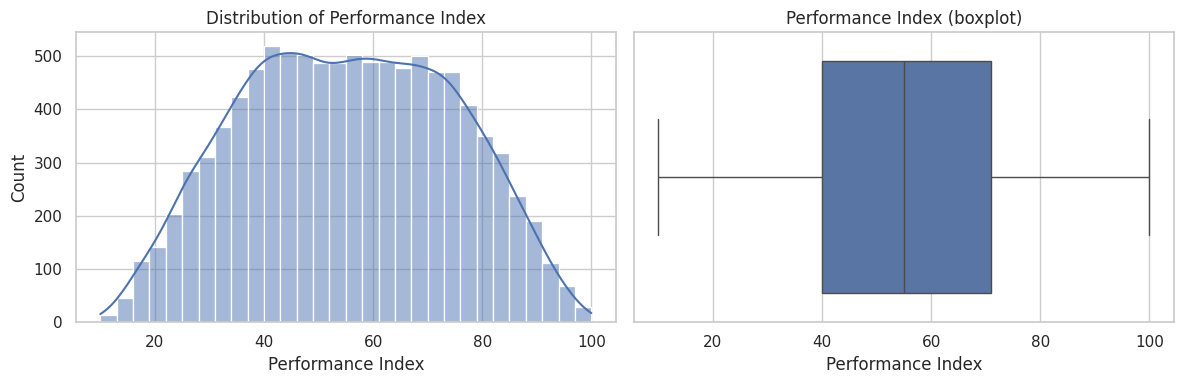

Skewness: -0.002


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Performance Index"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribution of Performance Index")
sns.boxplot(x=df["Performance Index"], ax=ax[1])
ax[1].set_title("Performance Index (boxplot)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["Performance Index"].skew(), 3))

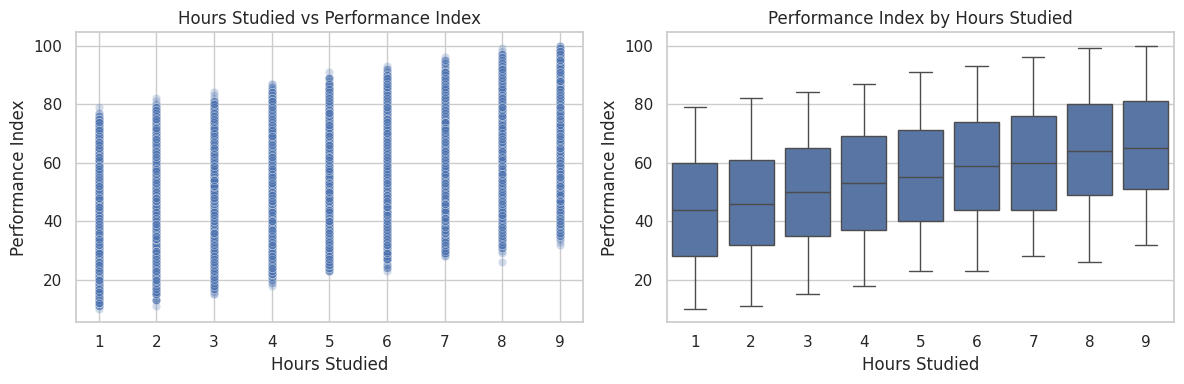

Correlation: 0.374


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Hours Studied", y="Performance Index", alpha=0.25, ax=ax[0])
ax[0].set_title("Hours Studied vs Performance Index")
sns.boxplot(data=df, x="Hours Studied", y="Performance Index", ax=ax[1])
ax[1].set_title("Performance Index by Hours Studied")
plt.tight_layout(); plt.show()
print("Correlation:", round(df["Hours Studied"].corr(df["Performance Index"]), 3))

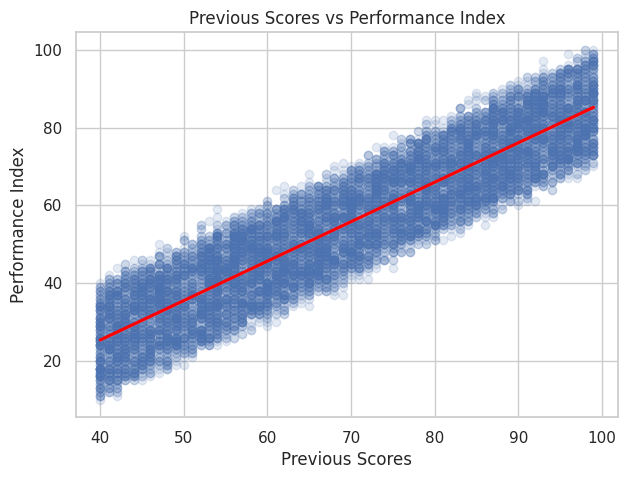

Correlation: 0.915


In [7]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="Previous Scores", y="Performance Index",
            scatter_kws={"alpha": 0.15}, line_kws={"color": "red"})
plt.title("Previous Scores vs Performance Index"); plt.show()
print("Correlation:", round(df["Previous Scores"].corr(df["Performance Index"]), 3))

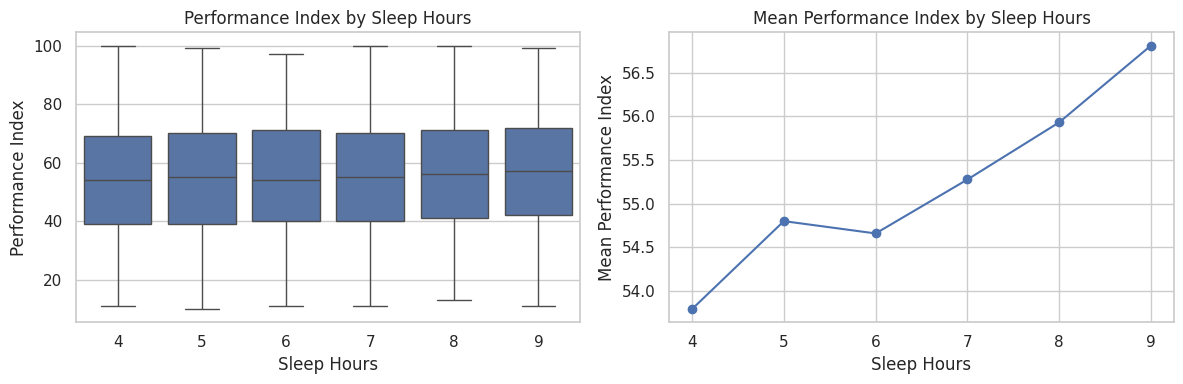

Correlation: 0.048


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Sleep Hours", y="Performance Index", ax=ax[0])
ax[0].set_title("Performance Index by Sleep Hours")
df.groupby("Sleep Hours")["Performance Index"].mean().plot(marker="o", ax=ax[1])
ax[1].set_title("Mean Performance Index by Sleep Hours"); ax[1].set_ylabel("Mean Performance Index")
plt.tight_layout(); plt.show()
print("Correlation:", round(df["Sleep Hours"].corr(df["Performance Index"]), 3))

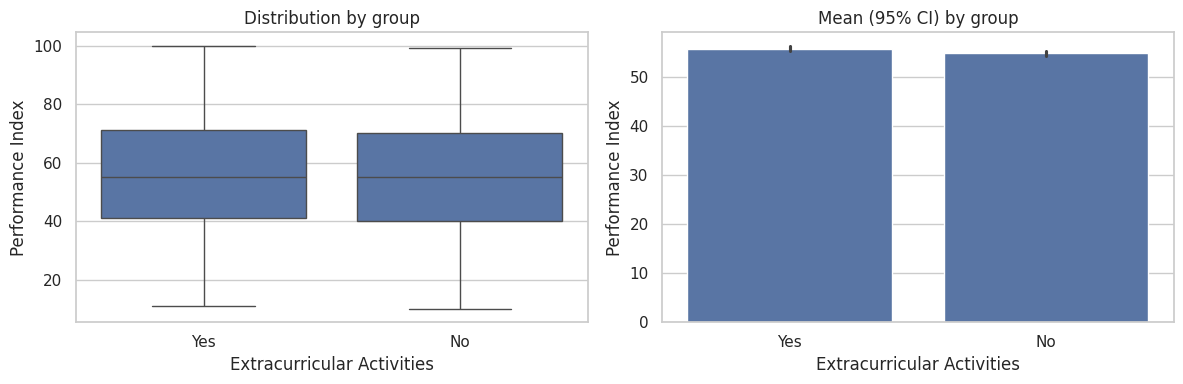

                            count   mean    std
Extracurricular Activities                     
No                           5052 54.759 19.152
Yes                          4948 55.701 19.264


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Extracurricular Activities", y="Performance Index", ax=ax[0])
sns.barplot(data=df, x="Extracurricular Activities", y="Performance Index", errorbar="ci", ax=ax[1])
ax[0].set_title("Distribution by group"); ax[1].set_title("Mean (95% CI) by group")
plt.tight_layout(); plt.show()
print(df.groupby("Extracurricular Activities")["Performance Index"].agg(["count", "mean", "std"]))

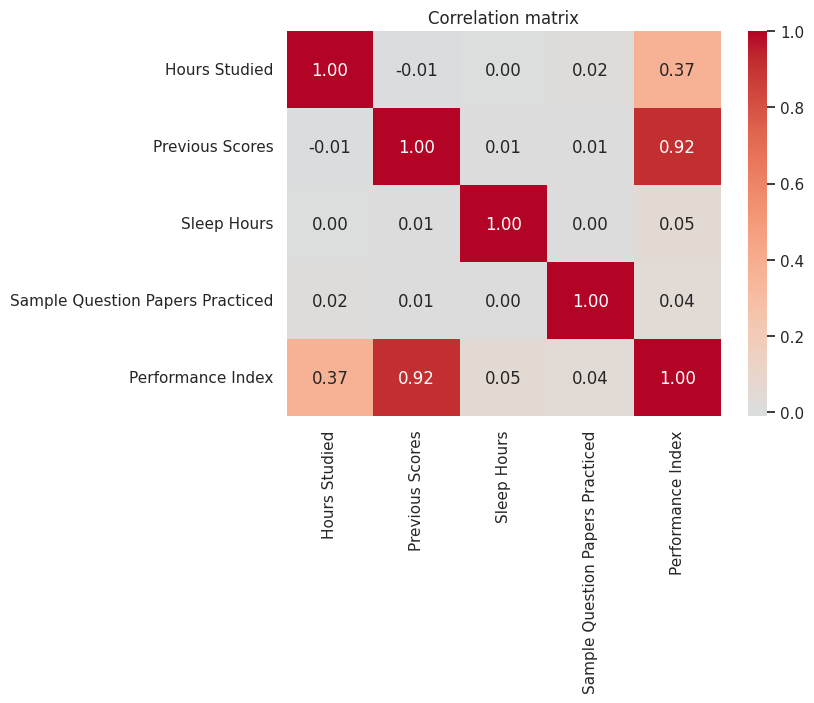

Previous Scores                    0.915
Hours Studied                      0.374
Sleep Hours                        0.048
Sample Question Papers Practiced   0.043
Name: Performance Index, dtype: float64


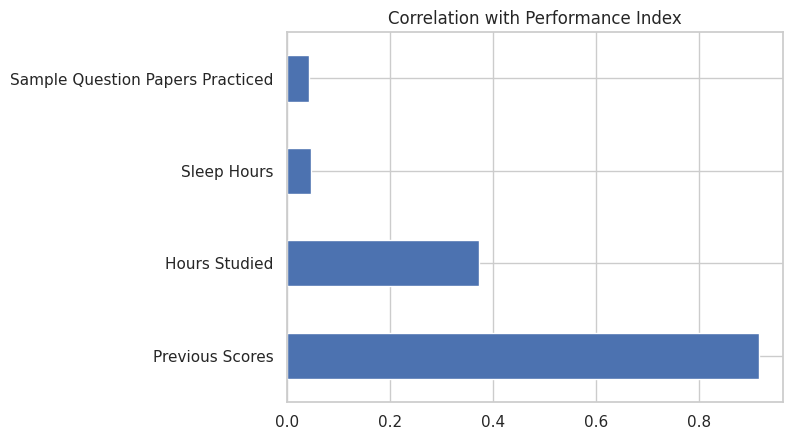

In [10]:
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

target_corr = corr["Performance Index"].drop("Performance Index").sort_values(ascending=False)
print(target_corr)
target_corr.plot(kind="barh", title="Correlation with Performance Index"); plt.show()

In [11]:
# Missing values / duplicates
print("Missing values:", df.isnull().sum().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)   # no-ops if data is already clean

categorical = df.select_dtypes(include="object").columns.tolist()
numerical = df.select_dtypes(include="number").columns.drop("Performance Index").tolist()
print("Categorical:", categorical)
print("Numerical features:", numerical)


Missing values: 0
Categorical: ['Extracurricular Activities']
Numerical features: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']


In [12]:
# Encode the binary categorical column (Yes/No -> 1/0)
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})
assert df["Extracurricular Activities"].isnull().sum() == 0

features = ["Hours Studied", "Previous Scores", "Sleep Hours",
            "Sample Question Papers Practiced", "Extracurricular Activities"]
X = df[features]
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (7898, 5)  Test: (1975, 5)


In [13]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

coef = pd.Series(model.coef_, index=features).sort_values(ascending=False)
print("Intercept:", round(model.intercept_, 4))
print(coef)

Intercept: -33.9813
Hours Studied                      2.851
Previous Scores                    1.018
Extracurricular Activities         0.574
Sleep Hours                        0.472
Sample Question Papers Practiced   0.189
dtype: float64


In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

pd.DataFrame({"Metric": ["MAE", "MSE", "RMSE", "R²"], "Value": [mae, mse, rmse, r2]}).set_index("Metric")

,Value
Metric,
MAE,1.647
MSE,4.306
RMSE,2.075
R²,0.988


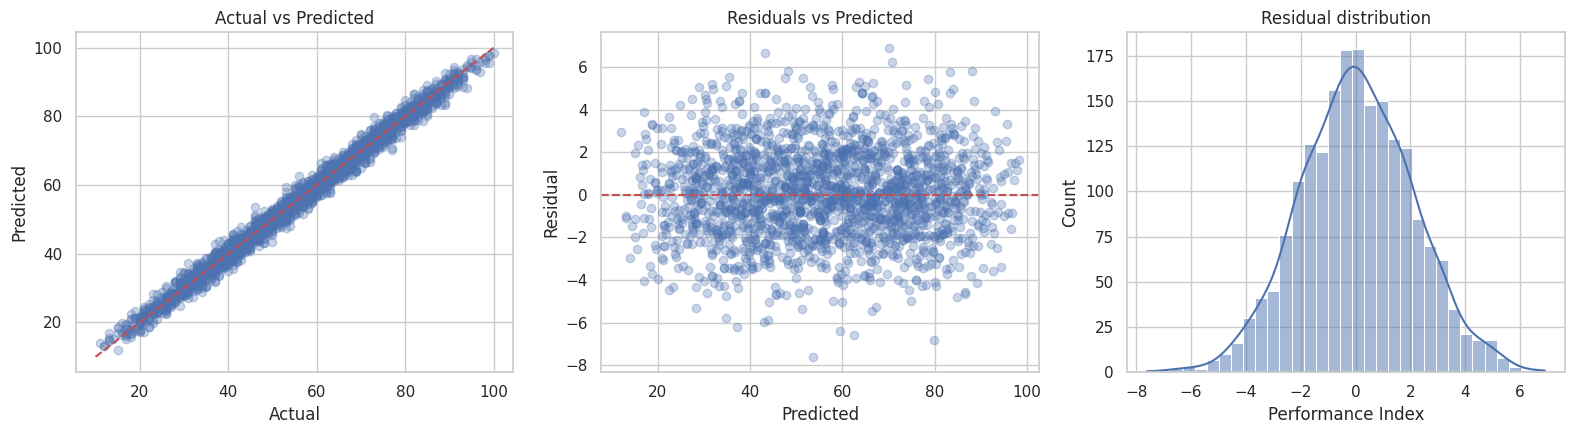

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.3)
lims = [y.min(), y.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs Predicted")

resid = y_test - y_pred
ax[1].scatter(y_pred, resid, alpha=0.3); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs Predicted")

sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

In [16]:
print(f"Average error (MAE): {mae:.2f} points on a scale of {y.min():.0f}-{y.max():.0f}")
print(f"Typical error (RMSE): {rmse:.2f} points")
print(f"R²: {r2:.4f} -> the model explains {r2*100:.1f}% of the variance in the test set")
print(f"Residual mean: {resid.mean():.3f} (close to 0 = no systematic bias)")

Average error (MAE): 1.65 points on a scale of 10-100
Typical error (RMSE): 2.08 points
R²: 0.9884 -> the model explains 98.8% of the variance in the test set
Residual mean: 0.061 (close to 0 = no systematic bias)


In [17]:
new_students = pd.DataFrame({
    "Hours Studied":                    [2,  5,  8,  9,  4,  7],
    "Previous Scores":                  [50, 65, 90, 95, 40, 78],
    "Extracurricular Activities":       [0,  1,  1,  0,  1,  0],
    "Sleep Hours":                      [5,  7,  8,  6,  9,  7],
    "Sample Question Papers Practiced": [1,  4,  8,  9,  0,  5],
})[features]

new_students["Predicted Performance Index"] = model.predict(new_students).round(2)
new_students

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities,Predicted Performance Index
0,2,50,5,1,0,25.190
1,5,65,7,4,1,51.100
2,8,90,8,8,1,86.350
3,9,95,6,9,0,92.960
4,4,40,9,0,1,22.980
5,7,78,7,5,0,69.660


In [18]:
strongest_corr = target_corr.abs().idxmax()
std_coef = pd.Series(model.coef_ * X_train.std().values, index=features).abs().sort_values(ascending=False)

print("Q1. Strongest relationships")
print(f"  Highest |correlation| with target: {strongest_corr} ({target_corr[strongest_corr]:.3f})")
print("  Standardised effect size (|coef| x feature std), ranked:")
print(std_coef.round(3).to_string())

print(f"\nQ2. Study hours: each extra hour studied changes the predicted index by "
      f"{coef['Hours Studied']:+.2f} points, holding other features constant.")

print(f"\nQ3. Previous scores: correlation {target_corr['Previous Scores']:.3f}; each extra "
      f"previous-score point changes the prediction by {coef['Previous Scores']:+.2f}.")

print(f"\nQ4. Accuracy: R² = {r2:.4f}, MAE = {mae:.2f}, RMSE = {rmse:.2f} on the held-out test set.")

Q1. Strongest relationships
  Highest |correlation| with target: Previous Scores (0.915)
  Standardised effect size (|coef| x feature std), ranked:
Previous Scores                    17.621
Hours Studied                       7.374
Sleep Hours                         0.802
Sample Question Papers Practiced    0.540
Extracurricular Activities          0.287

Q2. Study hours: each extra hour studied changes the predicted index by +2.85 points, holding other features constant.

Q3. Previous scores: correlation 0.915; each extra previous-score point changes the prediction by +1.02.

Q4. Accuracy: R² = 0.9884, MAE = 1.65, RMSE = 2.08 on the held-out test set.


**Q5. Limitations**

- **Synthetic data:** the data was generated for practice, so relationships are cleaner than in real life and the conclusions do not transfer to real students.
- **Correlation is not causation:** coefficients describe associations in this dataset, not proven effects of changing a habit.
- **Linearity assumption:** the model assumes a constant effect per unit of each feature. Check the residual plots for curvature or a changing spread.
- **Limited features:** motivation, teaching quality, family background and health are missing, so a very high R² here would not carry over to real-world data.
- **Discrete, bounded inputs:** hours, sleep and papers take a small set of integer values, and predictions outside the training ranges (extrapolation) are unreliable.
- **Bounded target:** the Performance Index ranges 10–100, but a linear model can predict values outside that range for extreme inputs.
- **Single split:** results come from one 80/20 split. Cross-validation would give a more robust estimate.

In [19]:
from sklearn.model_selection import cross_val_score
cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold CV R²:", cv.round(4), "| mean:", cv.mean().round(4))

5-fold CV R²: [0.9888 0.9882 0.989  0.9891 0.9882] | mean: 0.9887
